In [8]:
from pathlib import Path
import pandas as pd

folders = [
    "../data/processed",
    "../opt",
    "../sim",
    "../config",
    "../docs"
]

for folder in folders:
    path = Path(folder)
    print(f"\n{folder}")

    if path.exists():
        for item in sorted(path.iterdir()):
            print("  ", item.name)
    else:
        print("   Folder not found")


../data/processed
   core_edges.csv
   core_later_legs.csv
   core_location_coverage.csv
   core_location_review.csv
   core_nodes.csv
   core_train_legs.csv
   core_training_comparison.csv
   distance_bucket_summary.csv
   geocode_cache.json
   geocode_cache_threshold3.json
   hub_daily_departures.csv
   hub_location_coverage_threshold3.csv
   hub_stats.csv
   hub_stats_threshold3.csv
   hubs.csv
   hubs_threshold3.csv
   hubs_threshold3_before_manual_review.csv
   hubs_threshold3_review.csv
   hubs_threshold3_working.csv
   lanes.csv
   legs.csv
   legs_enriched.csv
   olist_late_by_state.csv
   olist_late_overall.csv
   preds_cal_test_v1.csv
   preds_test.csv
   preds_test_intervals_v1.csv
   preds_test_intervals_v2.csv
   priority_city_candidates.csv
   priority_hub_postal_candidates.csv
   rain_comparison_summary.csv
   rain_lane_comparison.csv
   rain_lane_sensitivity.csv
   rain_threshold_sensitivity.csv
   reviewed_city_corrections.csv
   threshold_sensitivity.csv
   unnamed_h

In [9]:
import sys
sys.path.append("..")
import pandas as pd
from sim.simulate import build_neighbors, simulate_cascade, single_hub_failures

edges = [("H1","H2"), ("H1","H3"), ("H2","H4"), ("H3","H4"), ("H4","H5"),
         ("H5","H6"), ("H5","H7"), ("H6","H8"), ("H7","H8")]
cap  = {"H1":100, "H2":100, "H3":100, "H4":150, "H5":120, "H6":100, "H7":100, "H8":100}
load = {"H1":60,  "H2":70,  "H3":70,  "H4":100, "H5":80,  "H6":60,  "H7":60,  "H8":50}
nb = build_neighbors(edges)

# Test 1: H4 fails, a calm case
r1 = simulate_cascade(cap, load, nb, ["H4"])
assert r1["n_failed"] == 1 and r1["unserved_load"] == 0 and r1["converged"]
assert abs(r1["final_load"]["H2"] - 100) < 1e-6
assert abs(r1["final_load"]["H3"] - 100) < 1e-6
assert abs(r1["final_load"]["H5"] - 120) < 1e-6

# Test 2: H4 carries more load, so the whole network collapses
load2 = {**load, "H4": 120}
r2 = simulate_cascade(cap, load2, nb, ["H4"])
assert r2["n_failed"] == 8 and r2["n_rounds"] == 4
assert abs(r2["unserved_load"] - 570) < 1e-6
display(pd.DataFrame(r2["rounds"]))

# Test 3: same stress, but hubs tolerate 10% overload
r3 = simulate_cascade(cap, load2, nb, ["H4"], tolerance=1.1)
assert r3["n_failed"] == 1 and r3["unserved_load"] == 0

# Test 4: conservation holds for every single-hub failure
for h in cap:
    assert simulate_cascade(cap, load2, nb, [h])["conserved"]

print("all tests passed")

,round,newly_failed,load_shifted,total_failed
0,0,[H4],120.0,1
1,1,"[H2, H3, H5]",340.0,4
2,2,"[H1, H6, H7]",520.0,7
3,3,[H8],298.0,8


all tests passed


In [10]:
sweep = single_hub_failures(cap, load2, nb)
sweep

,hub,own_load,n_failed,n_rounds,unserved_share,max_util_alive
0,H4,120,8,4,1.0,0.000
1,H1,60,1,1,0.0,1.000
2,H2,70,1,1,0.0,1.000
3,H3,70,1,1,0.0,1.000
4,H5,80,1,1,0.0,0.945
5,H6,60,1,1,0.0,0.889
6,H7,60,1,1,0.0,0.889
7,H8,50,1,1,0.0,0.850


In [11]:
import pandas as pd
from sim.simulate import build_neighbors, simulate_cascade, single_hub_failures

# 1. Load Person A's core network
nodes = pd.read_csv("../data/processed/core_nodes.csv")
edges = pd.read_csv("../data/processed/core_edges.csv")

print("Nodes shape:", nodes.shape)
print("Edges shape:", edges.shape)
display(nodes.head(3))
display(edges.head(3))

Nodes shape: (100, 23)
Edges shape: (292, 4)


,hub,name,search_city,search_state,match,latitude,longitude,coordinate_method,review_evidence,located,...,legs_per_day_p95,capacity_est,city,matched_name,matched_state,error,observed_days,active_days,capacity_unit,capacity_method
0,IND000000ACB,Gurgaon_Bilaspur_HB (Haryana),Gurugram,Haryana,city+state,28.46010,77.02635,previous_city_match_not_revalidated,NaN,True,...,52.05,53,Gurgaon,NaN,NaN,NaN,14,14,outgoing_legs_per_day,ceil_training_daily_outgoing_p95
1,IND562132AAA,Bangalore_Nelmngla_H (Karnataka),Bengaluru,Karnataka,city+state,12.97194,77.59369,previous_city_match_not_revalidated,NaN,True,...,38.70,39,Bangalore,NaN,NaN,NaN,14,14,outgoing_legs_per_day,ceil_training_daily_outgoing_p95
2,IND501359AAE,Hyderabad_Shamshbd_H (Telangana),Hyderabad,Telangana,city+state,17.38405,78.45636,previous_city_match_not_revalidated,NaN,True,...,12.35,13,Hyderabad,NaN,NaN,NaN,14,14,outgoing_legs_per_day,ceil_training_daily_outgoing_p95


,source_center,destination_center,leg_count,trip_count
0,IND000000AAL,IND411033AAA,14,14
1,IND000000ACA,IND144001AAB,13,13
2,IND000000ACA,IND160002AAC,59,59


In [13]:
# 1. Build capacity dictionary from nodes
capacity = nodes.set_index("hub")["capacity_est"].to_dict()

# 2. Define baseline load (60% utilization baseline)
load = {h: cap * 0.6 for h, cap in capacity.items()}

# 3. Build edge neighbor list from edges (using 'edges' instead of 'edges_df')
edges_list = list(zip(edges["source_center"], edges["destination_center"]))
neighbors = build_neighbors(edges_list)

# 4. Run single hub failure sweep across the 100 real hubs
real_sweep = single_hub_failures(capacity, load, neighbors, tolerance=1.0)

print("Top 10 Most Critical Hubs in Person A's Core Network:")
display(real_sweep.head(10))

Top 10 Most Critical Hubs in Person A's Core Network:


,hub,own_load,n_failed,n_rounds,unserved_share,max_util_alive
0,IND000000ACB,31.8,1,1,0.0,0.720
1,IND562132AAA,23.4,1,1,0.0,0.690
2,IND501359AAE,7.8,1,1,0.0,0.639
3,IND712311AAA,8.4,1,1,0.0,0.681
4,IND421302AAG,23.4,1,1,0.0,0.709
5,IND160002AAC,9.6,1,1,0.0,0.691
6,IND131028AAB,5.4,1,1,0.0,0.637
7,IND411033AAA,14.4,1,1,0.0,0.678
8,IND600056AAB,9.6,1,1,0.0,0.660
9,IND302014AAA,1.8,1,1,0.0,0.617


In [14]:
# Stress Test: Increase baseline load to 90% of capacity
stressed_load = {h: cap * 0.9 for h, cap in capacity.items()}

# Run sweep under higher stress
stressed_sweep = single_hub_failures(capacity, stressed_load, neighbors, tolerance=1.0)

print("Top 10 Most Vulnerable Hubs under 90% Load Stress:")
display(stressed_sweep.head(10))

# Check how many hubs cause multi-hub cascades when stressed
multi_fail = stressed_sweep[stressed_sweep["n_failed"] > 1]
print(f"Hubs causing multi-hub cascades under stress: {len(multi_fail)}")

Top 10 Most Vulnerable Hubs under 90% Load Stress:


,hub,own_load,n_failed,n_rounds,unserved_share,max_util_alive
0,IND000000ACB,47.7,97,4,1.0,0.0
1,IND562132AAA,35.1,97,4,1.0,0.0
2,IND712311AAA,12.6,97,5,1.0,0.0
3,IND421302AAG,35.1,97,4,1.0,0.0
4,IND160002AAC,14.4,97,5,1.0,0.0
5,IND411033AAA,21.6,97,4,1.0,0.0
6,IND560099AAB,25.2,97,5,1.0,0.0
7,IND000000ACA,5.4,97,6,1.0,0.0
8,IND560300AAA,16.2,97,5,1.0,0.0
9,IND121004AAB,8.1,97,5,1.0,0.0


Hubs causing multi-hub cascades under stress: 38


In [15]:
from pathlib import Path

OUT = Path("../experiments/day4")
OUT.mkdir(parents=True, exist_ok=True)

# Save the real network single-hub stress sweep
real_sweep.to_csv(OUT / "real_network_hub_criticality_v1.csv", index=False)
print("Day 4 simulation results successfully saved to experiments/day4/")

Day 4 simulation results successfully saved to experiments/day4/


# SupplyShield: Cascade Simulator Rules & Specification (v1)

## 1. Core Rules (Motter-Lai Style Load Redistribution)
1. **Hub Representation:** Every hub has a defined **capacity** and current **load**.
2. **Initial Disruption:** A scenario initializes by failing one or more target hubs.
3. **Load Redistribution:** A failed hub distributes its accumulated load to its **alive neighbors** in direct proportion to their **spare room** (capacity minus current load). If all neighboring hubs are at or over capacity, the load is shared in proportion to their total capacities.
4. **Failure Criterion:** A hub fails if its updated load exceeds `tolerance * capacity` (where tolerance represents the resilience threshold).
5. **Iterative Rounds:** The process repeats in discrete rounds until no new hubs fail or `max_rounds` is reached.
6. **Unserved Load:** Any load originating from a failed hub that has no remaining alive neighbors to route to is classified as **unserved load**.

---

## 2. Parameters
* **`tolerance`**: Default `1.0` (hubs fail immediately when load exceeds capacity; e.g., `1.1` allows a 10% overload buffer).
* **`max_rounds`**: Default `20` (maximum propagation steps for cascade evaluation).

---

## 3. Input & Output Formats
* **Inputs:** 
  * `capacity`: Dictionary mapping hub identifiers to numerical capacity values.
  * `load`: Dictionary mapping hub identifiers to baseline numerical load values.
  * `neighbors`: Adjacency list mapping each hub to its connected peers.
  * `initial_failed`: List of hub IDs targeted for initial failure.
* **Outputs:** 
  * `failed`: Sorted list of all hubs that failed during the cascade.
  * `n_failed`: Total count of failed hubs.
  * `n_rounds`: Total number of rounds taken for the cascade to settle.
  * `rounds`: Step-by-step audit trail of newly failed hubs and shifted loads per round.
  * `unserved_load`: Total load that could not be redistributed.
  * `unserved_share`: Ratio of unserved load to total network load.
  * `conserved`: Boolean verification flag ensuring total load equals unserved load plus alive load.

---

## 4. Modeling Disclaimer
> Capacities and baseline loads are derived or synthetic. The redistribution rule (proportional to spare room) and the tolerance are modelling assumptions, not observed behavior. Results show how fragile the network would be under these assumptions.

In [16]:
cap = dict(zip(nodes["hub"], nodes["capacity_est"].astype(float)))
hubs = list(nodes["hub"])
nb = build_neighbors(list(zip(edges["source_center"], edges["destination_center"])))

unknown = (set(edges["source_center"]) | set(edges["destination_center"])) - set(hubs)
print("Edge endpoints not in nodes:", len(unknown))
print("Hubs with capacity 0:", int((nodes["capacity_est"] == 0).sum()))
print("Hubs with capacity <= 5:", int((nodes["capacity_est"] <= 5).sum()))
print("Hubs without any lane:", [h for h in hubs if h not in nb])

seen, comps = set(), []
for h in hubs:
    if h in seen:
        continue
    stack, comp = [h], set()
    while stack:
        x = stack.pop()
        if x in comp:
            continue
        comp.add(x)
        stack.extend(n for n in nb.get(x, []) if n not in comp)
    seen |= comp
    comps.append(comp)
print("Connected components (sizes):", sorted(map(len, comps), reverse=True))

deg = pd.Series({h: len(nb.get(h, [])) for h in hubs})
print("\nDegree (number of neighbours):")
print(deg.describe().round(2))
print("\nCapacity:")
print(nodes["capacity_est"].describe().round(2))

Edge endpoints not in nodes: 0
Hubs with capacity 0: 3
Hubs with capacity <= 5: 77
Hubs without any lane: []
Connected components (sizes): [100]

Degree (number of neighbours):
count    100.00
mean       3.66
std        4.89
min        1.00
25%        1.00
50%        2.00
75%        3.25
max       30.00
dtype: float64

Capacity:
count    100.00
mean       5.57
std        8.45
min        0.00
25%        2.00
50%        3.00
75%        5.00
max       53.00
Name: capacity_est, dtype: float64


In [17]:
import numpy as np

def trigger_table(cap, load, nb, tol=1.0):
    rows = []
    for h in cap:
        spare = sum(max(tol * cap[j] - load[j], 0) for j in nb.get(h, []))
        rows.append({
            "hub": h, 
            "degree": len(nb.get(h, [])), 
            "own_load": round(load[h], 2), 
            "neighbor_spare": round(spare, 2), 
            "load_to_spare": load[h] / spare if spare > 0 else np.inf
        })
    return pd.DataFrame(rows).sort_values("load_to_spare", ascending=False).reset_index(drop=True)

load90 = {h: 0.9 * c for h, c in cap.items()}
tt = trigger_table(cap, load90, nb)
n_pred = int(((tt["degree"] > 0) & (tt["load_to_spare"] > 1)).sum())
print("Hubs predicted to cascade (load > neighbour spare):", n_pred, "| simulator said: 38")
display(tt.head(10))

Hubs predicted to cascade (load > neighbour spare): 39 | simulator said: 38


,hub,degree,own_load,neighbor_spare,load_to_spare
0,IND560064AAD,1,2.7,0.6,4.500000
1,IND462011AAA,1,1.8,0.5,3.600000
2,IND600032AAB,3,8.1,2.3,3.521739
3,IND532001AAB,1,0.9,0.3,3.000000
4,IND000000ACA,2,5.4,1.9,2.842105
5,IND380054AAA,1,1.8,0.7,2.571429
6,IND560099AAB,11,25.2,10.2,2.470588
7,IND600044AAE,1,3.6,1.6,2.250000
8,IND500010AAB,1,2.7,1.3,2.076923
9,IND121001AAA,1,1.8,0.9,2.000000


In [18]:
train = pd.read_csv("../data/datasplit/train_legs_v1.csv", parse_dates=["od_start_time"])
core = sorted(hubs)
t = train[train["source_center"].isin(core)].copy()
t["date"] = t["od_start_time"].dt.date
days = pd.date_range(train["od_start_time"].dt.date.min(), train["od_start_time"].dt.date.max()).date
idx = pd.MultiIndex.from_product([core, days], names=["source_center", "date"])

daily = (t.groupby(["source_center", "date"]).size().rename("legs")
         .reindex(idx, fill_value=0).reset_index())
stats = daily.groupby("source_center")["legs"].agg(
    mean_legs="mean", 
    p95_legs=lambda s: s.quantile(0.95), 
    max_legs="max"
)

chk = stats.join(nodes.set_index("hub")[["legs_per_day_p95", "capacity_est"]])
print("My p95 vs Person A's p95 (difference):")
print((chk["p95_legs"] - chk["legs_per_day_p95"]).describe().round(3))

chk["util_mean"] = np.where(chk["capacity_est"] > 0, chk["mean_legs"] / chk["capacity_est"], np.nan)
print("\nTypical utilization (mean daily legs / capacity):")
print(chk["util_mean"].describe().round(3))

# Run single failure sweep with real loads
load_data = {h: float(stats["mean_legs"].get(h, 0.0)) for h in cap}
real = single_hub_failures(cap, load_data, nb).round(3)
print("Hubs causing multi-hub cascades with real loads:", int((real["n_failed"] > 1).sum()))
display(real.head(10))

My p95 vs Person A's p95 (difference):
count    100.000
mean       1.498
std        2.599
min       -1.000
25%        0.000
50%        0.300
75%        2.000
max       13.750
dtype: float64

Typical utilization (mean daily legs / capacity):
count    97.000
mean      0.767
std       0.506
min       0.200
25%       0.444
50%       0.642
75%       0.933
max       2.600
Name: util_mean, dtype: float64
Hubs causing multi-hub cascades with real loads: 100


,hub,own_load,n_failed,n_rounds,unserved_share,max_util_alive
0,IND501359AAE,13.467,94,5,0.981,1.000
1,IND382430AAB,11.067,94,5,0.981,1.000
2,IND209304AAA,7.467,94,5,0.981,1.000
3,IND110044AAB,7.067,94,5,0.981,1.000
4,IND160102AAC,1.467,94,5,0.981,1.000
5,IND131028AAB,11.400,94,5,0.980,1.000
6,IND110037AAM,10.600,94,5,0.980,1.000
7,IND000000ACT,6.600,94,5,0.980,1.000
8,IND751002AAB,3.800,94,5,0.979,0.988
9,IND533106AAA,2.000,94,5,0.979,0.942


,stress,tolerance,share_hubs_cascading,mean_failed,max_failed,mean_unserved_share,non_converged
0,0.50,1.0,0.00,1.00,1,0.00,0
1,0.50,1.1,0.00,1.00,1,0.00,0
2,0.50,1.2,0.00,1.00,1,0.00,0
3,0.50,1.3,0.00,1.00,1,0.00,0
4,0.55,1.0,0.00,1.00,1,0.00,0
5,0.55,1.1,0.00,1.00,1,0.00,0
6,0.55,1.2,0.00,1.00,1,0.00,0
7,0.55,1.3,0.00,1.00,1,0.00,0
8,0.60,1.0,0.00,1.00,1,0.00,0
9,0.60,1.1,0.00,1.00,1,0.00,0


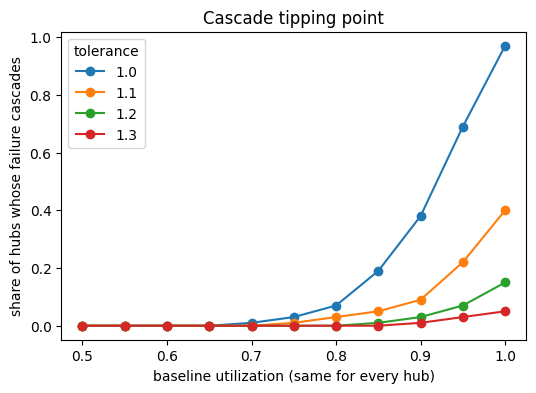

In [19]:
import matplotlib.pyplot as plt
from sim.simulate import simulate_cascade

def stress_sweep(levels, tolerances, cap, nb, max_rounds=30):
    rows = []
    for s in levels:
        load = {h: s * c for h, c in cap.items()}
        for tol in tolerances:
            res = [simulate_cascade(cap, load, nb, [h], tol, max_rounds) for h in cap]
            nf = np.array([r["n_failed"] for r in res])
            rows.append({
                "stress": round(s, 2),
                "tolerance": tol,
                "share_hubs_cascading": float((nf > 1).mean()),
                "mean_failed": float(nf.mean()),
                "max_failed": int(nf.max()),
                "mean_unserved_share": float(np.mean([r["unserved_share"] for r in res])),
                "non_converged": int(sum(not r["converged"] for r in res))
            })
    return pd.DataFrame(rows)

sw = stress_sweep(np.arange(0.50, 1.001, 0.05), [1.0, 1.1, 1.2, 1.3], cap, nb)
display(sw.round(3))

pv = sw.pivot(index="stress", columns="tolerance", values="share_hubs_cascading")
ax = pv.plot(marker="o", figsize=(6, 4))
ax.set_xlabel("baseline utilization (same for every hub)")
ax.set_ylabel("share of hubs whose failure cascades")
ax.set_title("Cascade tipping point")
plt.savefig("../docs/cascade_stress_curve_v1.png", dpi=150, bbox_inches="tight")
plt.show()

In [20]:
from pathlib import Path

OUT = Path("../experiments/day4")
OUT.mkdir(parents=True, exist_ok=True)

for name, df_ in [
    ("stress_sweep_v1.csv", sw.round(3)), 
    ("single_failure_real_loads_v1.csv", real), 
    ("trigger_table_stress90_v1.csv", tt)
]:
    p = OUT / name
    if not p.exists():
        df_.to_csv(p, index=False)
        print("Saved:", name)
    else:
        print("Exists, skipping:", name)

Saved: stress_sweep_v1.csv
Saved: single_failure_real_loads_v1.csv
Saved: trigger_table_stress90_v1.csv


In [21]:
load90 = {h: 0.9 * c for h, c in cap.items()}
sim_casc = {h for h in cap if simulate_cascade(cap, load90, nb, [h])["n_failed"] > 1}
pred = set(tt[(tt["degree"] > 0) & (tt["load_to_spare"] > 1)]["hub"])
print("predicted but not simulated:", pred - sim_casc)
print("simulated but not predicted:", sim_casc - pred)
diff = (pred - sim_casc) | (sim_casc - pred)
tt[tt["hub"].isin(diff)]

predicted but not simulated: {'IND140901AAA'}
simulated but not predicted: set()


,hub,degree,own_load,neighbor_spare,load_to_spare
38,IND140901AAA,3,1.8,1.8,1.0


In [22]:
core_set = set(nodes["hub"])
tr = pd.read_csv("../data/datasplit/train_legs_v1.csv", parse_dates=["od_start_time"])
inside = tr[tr["source_center"].isin(core_set) & tr["destination_center"].isin(core_set)].copy()
inside["date"] = inside["od_start_time"].dt.date
days = pd.date_range(tr["od_start_time"].dt.date.min(), tr["od_start_time"].dt.date.max()).date
print("days:", len(days), "| core-to-core training legs:", len(inside),
      "| A's observed_days:", nodes["observed_days"].unique())

idx = pd.MultiIndex.from_product([sorted(core_set), days], names=["source_center", "date"])
daily2 = (inside.groupby(["source_center", "date"]).size().rename("legs")
          .reindex(idx, fill_value=0).reset_index())
st = daily2.groupby("source_center")["legs"].agg(mean_legs="mean",
                                                 p95_mine=lambda s: s.quantile(0.95))

cmp_ = st.join(nodes.set_index("hub")[["legs_per_day_p95", "capacity_est"]])
d = cmp_["p95_mine"] - cmp_["legs_per_day_p95"]
print(d.describe().round(3))
print("share of hubs with |difference| < 0.5:", round((d.abs() < 0.5).mean(), 3))

days: 15 | core-to-core training legs: 4869 | A's observed_days: [14]
count    100.000
mean      -0.030
std        0.247
min       -1.000
25%       -0.050
50%        0.000
75%        0.000
max        1.000
dtype: float64
share of hubs with |difference| < 0.5: 0.91


In [23]:
cap_a  = dict(zip(nodes["hub"], nodes["capacity_est"].astype(float)))
load_c = {h: float(st["mean_legs"].get(h, 0.0)) for h in cap_a}

util = pd.Series({h: load_c[h] / cap_a[h] for h in cap_a if cap_a[h] > 0})
print(util.describe().round(3))
print("hubs starting above capacity:", int((util > 1).sum()))

real2 = single_hub_failures(cap_a, load_c, nb).round(3)
print("hubs causing multi-hub cascades:", int((real2["n_failed"] > 1).sum()))
real2.head(10)

count    97.000
mean      0.508
std       0.175
min       0.200
25%       0.356
50%       0.533
75%       0.667
max       0.867
dtype: float64
hubs starting above capacity: 0
hubs causing multi-hub cascades: 99


,hub,own_load,n_failed,n_rounds,unserved_share,max_util_alive
0,IND000000ACB,37.133,2,2,0.0,0.867
1,IND562132AAA,29.067,2,2,0.0,0.867
2,IND501359AAE,7.267,2,2,0.0,0.867
3,IND712311AAA,7.933,2,2,0.0,0.867
4,IND421302AAG,27.000,2,2,0.0,0.867
5,IND160002AAC,12.133,2,2,0.0,0.911
6,IND131028AAB,6.133,2,2,0.0,0.867
7,IND411033AAA,15.933,2,2,0.0,0.867
8,IND600056AAB,9.933,2,2,0.0,0.867
9,IND302014AAA,1.400,2,2,0.0,0.867


In [24]:
import networkx as nx

G = nx.Graph()
G.add_edges_from(zip(edges["source_center"], edges["destination_center"]))
comp = pd.DataFrame({
    "betweenness": pd.Series(nx.betweenness_centrality(G)),
    "pagerank": pd.Series(nx.pagerank(G)),
    "degree": pd.Series(dict(G.degree()))
})
comp["capacity"] = pd.Series(cap_a)
comp["n_failed"] = real2.set_index("hub")["n_failed"]
print(comp.corr(method="spearman").round(2)["n_failed"])

betweenness    0.07
pagerank       0.16
degree         0.11
capacity       0.17
n_failed       1.00
Name: n_failed, dtype: float64


In [27]:
cap_exact = dict(zip(nodes["hub"], nodes["legs_per_day_p95"].astype(float)))
lv = np.arange(0.5, 1.001, 0.05)
sw_ceil  = stress_sweep(lv, [1.0, 1.1], cap_a, nb)
sw_exact = stress_sweep(lv, [1.0, 1.1], cap_exact, nb)
cmp2 = sw_ceil.merge(sw_exact, on=["stress", "tolerance"], suffixes=("_ceil", "_exact"))
cmp2[["stress", "tolerance", "share_hubs_cascading_ceil", "share_hubs_cascading_exact"]].round(3)

,stress,tolerance,share_hubs_cascading_ceil,share_hubs_cascading_exact
0,0.50,1.0,0.00,0.00
1,0.50,1.1,0.00,0.00
2,0.55,1.0,0.00,0.00
3,0.55,1.1,0.00,0.00
4,0.60,1.0,0.00,0.00
5,0.60,1.1,0.00,0.00
6,0.65,1.0,0.00,0.00
7,0.65,1.1,0.00,0.00
8,0.70,1.0,0.01,0.00
9,0.70,1.1,0.00,0.00


In [37]:
OUT = Path("../experiments/day4")
OUT.mkdir(parents=True, exist_ok=True)

for name, df_ in [
    ("single_failure_real_loads_v2_consistent_units.csv", real2),
    ("cascade_vs_centrality_v1.csv", comp.reset_index().rename(columns={"index": "hub"}).round(4)),
    ("capacity_rounding_sensitivity_v1.csv", cmp2.round(3))
]:
    p = OUT / name
    if not p.exists():
        df_.to_csv(p, index=False)
        print("Saved:", name)
    else:
        print("Exists, skipping:", name)

Exists, skipping: single_failure_real_loads_v2_consistent_units.csv
Exists, skipping: cascade_vs_centrality_v1.csv
Exists, skipping: capacity_rounding_sensitivity_v1.csv


In [38]:
import numpy as np
import pandas as pd
from pathlib import Path

# 1. Identify any hubs starting above capacity
over = {h: (round(load_c[h], 3), cap_a[h]) for h in cap_a if load_c[h] > cap_a[h] + 1e-9}
print("Hubs starting above capacity (including capacity 0):", over)

# 2. Align capacities to match observed loads if needed, then rerun single hub failures
import math
cap_fixed = {h: max(c, float(math.ceil(load_c[h] - 1e-9))) for h, c in cap_a.items()}

real3 = single_hub_failures(cap_fixed, load_c, nb).round(3)
print("Hubs causing multi-hub cascades:", int((real3["n_failed"] > 1).sum()), "| largest cascade:", int(real3["n_failed"].max()))
display(real3.head(10))

# 3. Save corrected outputs as version 3
OUT = Path("../experiments/day4")
OUT.mkdir(parents=True, exist_ok=True)

real3.to_csv(OUT / "single_failure_real_loads_v3.csv", index=False)
print("Saved: single_failure_real_loads_v3.csv")

Hubs starting above capacity (including capacity 0): {'IND110095AAB': (0.067, 0.0)}
Hubs causing multi-hub cascades: 0 | largest cascade: 1


,hub,own_load,n_failed,n_rounds,unserved_share,max_util_alive
0,IND000000ACB,37.133,1,1,0.0,0.867
1,IND562132AAA,29.067,1,1,0.0,0.867
2,IND501359AAE,7.267,1,1,0.0,0.867
3,IND712311AAA,7.933,1,1,0.0,0.867
4,IND421302AAG,27.000,1,1,0.0,0.867
5,IND160002AAC,12.133,1,1,0.0,0.911
6,IND131028AAB,6.133,1,1,0.0,0.867
7,IND411033AAA,15.933,1,1,0.0,0.867
8,IND600056AAB,9.933,1,1,0.0,0.867
9,IND302014AAA,1.400,1,1,0.0,0.867


Saved: single_failure_real_loads_v3.csv


In [39]:
over = {h: (round(load_c[h], 3), cap_a[h]) for h in cap_a if load_c[h] > cap_a[h] + 1e-9}
print("hubs starting above capacity (including capacity 0):", over)

hubs starting above capacity (including capacity 0): {'IND110095AAB': (0.067, 0.0)}


In [40]:
import math
cap_fixed = {h: max(c, float(math.ceil(load_c[h] - 1e-9))) for h, c in cap_a.items()}
print("capacities raised:", {h: (cap_a[h], cap_fixed[h]) for h in cap_a if cap_fixed[h] != cap_a[h]})

real3 = single_hub_failures(cap_fixed, load_c, nb).round(3)
print("hubs causing multi-hub cascades:", int((real3["n_failed"] > 1).sum()),
      "| largest cascade:", int(real3["n_failed"].max()))
display(real3.head(10))

comp["n_failed"] = real3.set_index("hub")["n_failed"]
print(comp.corr(method="spearman").round(2)["n_failed"])

capacities raised: {'IND110095AAB': (0.0, 1.0)}
hubs causing multi-hub cascades: 0 | largest cascade: 1


,hub,own_load,n_failed,n_rounds,unserved_share,max_util_alive
0,IND000000ACB,37.133,1,1,0.0,0.867
1,IND562132AAA,29.067,1,1,0.0,0.867
2,IND501359AAE,7.267,1,1,0.0,0.867
3,IND712311AAA,7.933,1,1,0.0,0.867
4,IND421302AAG,27.000,1,1,0.0,0.867
5,IND160002AAC,12.133,1,1,0.0,0.911
6,IND131028AAB,6.133,1,1,0.0,0.867
7,IND411033AAA,15.933,1,1,0.0,0.867
8,IND600056AAB,9.933,1,1,0.0,0.867
9,IND302014AAA,1.400,1,1,0.0,0.867


betweenness   NaN
pagerank      NaN
degree        NaN
capacity      NaN
n_failed      NaN
Name: n_failed, dtype: float64


In [41]:
import numpy as np

cap_exact = dict(zip(nodes["hub"], nodes["legs_per_day_p95"].astype(float)))
lv = np.arange(0.5, 1.001, 0.05)
sw_ceil = stress_sweep(lv, [1.0, 1.1], cap_fixed, nb)
sw_exact = stress_sweep(lv, [1.0, 1.1], cap_exact, nb)

cmp2 = sw_ceil.merge(sw_exact, on=["stress", "tolerance"], suffixes=("_ceil", "_exact"))
print(cmp2[["stress", "tolerance", "share_hubs_cascading_ceil", "share_hubs_cascading_exact"]].to_string())

    stress  tolerance  share_hubs_cascading_ceil  share_hubs_cascading_exact
0     0.50        1.0                       0.00                        0.00
1     0.50        1.1                       0.00                        0.00
2     0.55        1.0                       0.00                        0.00
3     0.55        1.1                       0.00                        0.00
4     0.60        1.0                       0.00                        0.00
5     0.60        1.1                       0.00                        0.00
6     0.65        1.0                       0.00                        0.00
7     0.65        1.1                       0.00                        0.00
8     0.70        1.0                       0.01                        0.00
9     0.70        1.1                       0.00                        0.00
10    0.75        1.0                       0.03                        0.03
11    0.75        1.1                       0.01                        0.00